In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno

In [6]:
df = pd.read_csv("MentalHealthSurvey.csv")

In [8]:
df.head()

,gender,age,university,degree_level,degree_major,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,...,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity,stress_relief_activities
0,Male,20,PU,Undergraduate,Data Science,2nd year,3.0-3.5,Off-Campus,No,No Sports,...,5,4,5,4,3,2,1,1,2,"Religious Activities, Social Connections, Onli..."
1,Male,20,UET,Postgraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,No,1-3 times,...,5,4,4,1,3,3,3,3,4,Online Entertainment
2,Male,20,FAST,Undergraduate,Computer Science,3rd year,2.5-3.0,Off-Campus,No,1-3 times,...,5,5,5,3,4,2,3,3,1,"Religious Activities, Sports and Fitness, Onli..."
3,Male,20,UET,Undergraduate,Computer Science,3rd year,2.5-3.0,On-Campus,No,No Sports,...,3,5,4,4,1,5,5,5,3,Online Entertainment
4,Female,20,UET,Undergraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,Yes,No Sports,...,3,5,5,2,3,5,5,4,4,Online Entertainment


In [10]:
df.shape

(87, 21)

In [12]:
df.isna().count()

gender                      87
age                         87
university                  87
degree_level                87
degree_major                87
academic_year               87
cgpa                        87
residential_status          87
campus_discrimination       87
sports_engagement           87
average_sleep               87
study_satisfaction          87
academic_workload           87
academic_pressure           87
financial_concerns          87
social_relationships        87
depression                  87
anxiety                     87
isolation                   87
future_insecurity           87
stress_relief_activities    87
dtype: int64

In [14]:
df.columns

Index(['gender', 'age', 'university', 'degree_level', 'degree_major',
       'academic_year', 'cgpa', 'residential_status', 'campus_discrimination',
       'sports_engagement', 'average_sleep', 'study_satisfaction',
       'academic_workload ', 'academic_pressure', 'financial_concerns',
       'social_relationships', 'depression', 'anxiety', 'isolation',
       'future_insecurity', 'stress_relief_activities'],
      dtype='object')

In [16]:
df.describe()

,age,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity
count,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000
mean,19.942529,3.931034,3.885057,3.781609,3.390805,2.781609,3.218391,3.218391,3.241379,3.011494
std,1.623636,1.043174,0.854880,1.125035,1.400634,1.175578,1.367609,1.297809,1.405682,1.385089
min,17.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,19.000000,3.000000,3.000000,3.000000,2.500000,2.000000,2.000000,2.000000,2.000000,2.000000
50%,20.000000,4.000000,4.000000,4.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,21.000000,5.000000,4.500000,5.000000,5.000000,4.000000,4.000000,4.000000,4.500000,4.000000
max,26.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [18]:
'''

Lots of encoding to do, the main difficulty here will be the last row
we will need to seperate unique values, and encode them, though there 
are multiple values within each data point for "stress relief activities". 

Other than that we need to create a target variable. What we want is to
predict which variable is most important in predicting stress. We will
also want to create a stress variable, research is needed here on how to
quantify stress with the information we have. 



'''

df.iloc[:4,10:21]

,average_sleep,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity,stress_relief_activities
0,4-6 hrs,5,4,5,4,3,2,1,1,2,"Religious Activities, Social Connections, Onli..."
1,4-6 hrs,5,4,4,1,3,3,3,3,4,Online Entertainment
2,2-4 hrs,5,5,5,3,4,2,3,3,1,"Religious Activities, Sports and Fitness, Onli..."
3,4-6 hrs,3,5,4,4,1,5,5,5,3,Online Entertainment


In [20]:
def description(df):
    head = df.head(5)
    describe = df.describe()
    shape = df.shape
    missing_count = df.shape[0] - df.count() # Number of rows minus number of non-NA rows.
    missing_percentage = (missing_count/df.shape[0]*100).astype(int)
    data_types = df.dtypes
    target_counts = df.iloc[:,-1].value_counts() 

    print(f"Shape of Dataset:\n{shape}\n")
    print(f"Data Types of Columns:\n{data_types}\n")
    print(f"Target & Target Counts:\n{target_counts}\n")
    print(f"Missing Value Counts:\n{missing_count}\n")
    print(f"Missing Value Percentages:\n{missing_percentage}\n")
    print(f"First Five Rows\n{head}\n")

In [22]:
description(df)

Shape of Dataset:
(87, 21)

Data Types of Columns:
gender                      object
age                          int64
university                  object
degree_level                object
degree_major                object
academic_year               object
cgpa                        object
residential_status          object
campus_discrimination       object
sports_engagement           object
average_sleep               object
study_satisfaction           int64
academic_workload            int64
academic_pressure            int64
financial_concerns           int64
social_relationships         int64
depression                   int64
anxiety                      int64
isolation                    int64
future_insecurity            int64
stress_relief_activities    object
dtype: object

Target & Target Counts:
stress_relief_activities
Religious Activities                                                                                             10
Online Entertainment              

In [24]:
''' 

I have been tasked with gaining a better understanding of the first 6 features of our dataset

'gender', 'age', 'university', 'degree_level', 'degree_major'

'''

" \n\nI have been tasked with gaining a better understanding of the first 6 features of our dataset\n\n'gender', 'age', 'university', 'degree_level', 'degree_major'\n\n"

In [26]:
df_mC = df[['gender', 'age', 'university', 'degree_level', 'degree_major']]

In [28]:
df_mC.head()

,gender,age,university,degree_level,degree_major
0,Male,20,PU,Undergraduate,Data Science
1,Male,20,UET,Postgraduate,Computer Science
2,Male,20,FAST,Undergraduate,Computer Science
3,Male,20,UET,Undergraduate,Computer Science
4,Female,20,UET,Undergraduate,Computer Science


In [30]:
df_mC['gender'].unique()

array(['Male', 'Female'], dtype=object)

In [32]:
df['anxiety'].unique()

array([1, 3, 5, 4, 2])

In [34]:
df['age'].unique()

array([20, 26, 22, 23, 21, 19, 18, 17])

In [36]:
print(df_mC.columns)

Index(['gender', 'age', 'university', 'degree_level', 'degree_major'], dtype='object')


In [38]:
for col in df_mC.columns:
    print(df_mC[col].unique())

['Male' 'Female']
[20 26 22 23 21 19 18 17]
['PU' 'UET' 'FAST' 'COMSATS' 'NUST' 'VU' 'UMT' 'UOL' 'KUST']
['Undergraduate' 'Postgraduate']
['Data Science' 'Computer Science' 'Software Engineering'
 'Information Technology']


In [40]:
'''

Universities:

PU	University of the Punjab, commonly called Punjab University (Lahore)
UET	University of Engineering and Technology
FAST	National University of Computer and Emerging Sciences, commonly called FAST-NUCES
COMSATS	COMSATS University Islamabad, which has multiple campuses
NUST	National University of Sciences and Technology
VU	Virtual University of Pakistan
UMT	University of Management and Technology (Lahore)
UOL	The University of Lahore
KUST	Kohat University of Science and Technology



Based in Pakistan, affirmed by the dataset poster being based in Pakistan too. Lots of
these uni's are mainly based in Lahore, Kohat, and Islamabad. Though there is not enough
information to say this is 100% true, this is just an estimation. 

'''

"\n\nUniversities:\n\nPU\tUniversity of the Punjab, commonly called Punjab University (Lahore)\nUET\tUniversity of Engineering and Technology\nFAST\tNational University of Computer and Emerging Sciences, commonly called FAST-NUCES\nCOMSATS\tCOMSATS University Islamabad, which has multiple campuses\nNUST\tNational University of Sciences and Technology\nVU\tVirtual University of Pakistan\nUMT\tUniversity of Management and Technology (Lahore)\nUOL\tThe University of Lahore\nKUST\tKohat University of Science and Technology\n\n\n\nBased in Pakistan, affirmed by the dataset poster being based in Pakistan too. Lots of\nthese uni's are mainly based in Lahore, Kohat, and Islamabad. Though there is not enough\ninformation to say this is 100% true, this is just an estimation. \n\n"

# Age 

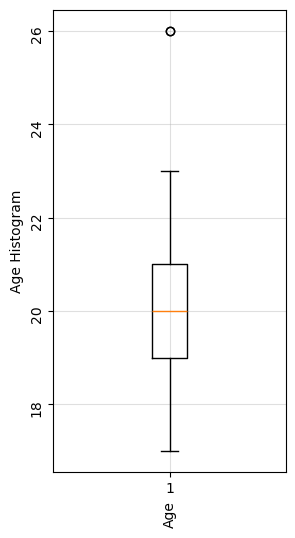

In [133]:
plt.figure(figsize=(3,6))
plt.boxplot(x=df['age'])
plt.xlabel("Age", rotation=90)
plt.yticks(rotation=90)
plt.grid(True, alpha=0.4)
plt.ylabel('Age Histogram', rotation=90)
plt.savefig('age_boxplot.png', bbox_inches='tight')
plt.show()

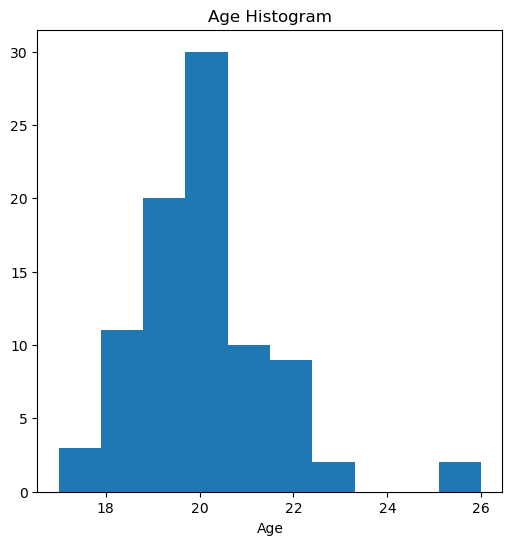

In [43]:
plt.figure(figsize=(6,6))
plt.hist(x=df['age'])
plt.xlabel("Age")
plt.title('Age Histogram')
plt.savefig('age_histogram.png', bbox_inches='tight')
plt.show()

In [107]:
age_1a=df.loc[df['anxiety']==1,'age']
age_2a=df.loc[df['anxiety']==2,'age']
age_3a=df.loc[df['anxiety']==3,'age']
age_4a=df.loc[df['anxiety']==4,'age']
age_5a=df.loc[df['anxiety']==5,'age']


<Figure size 600x600 with 0 Axes>

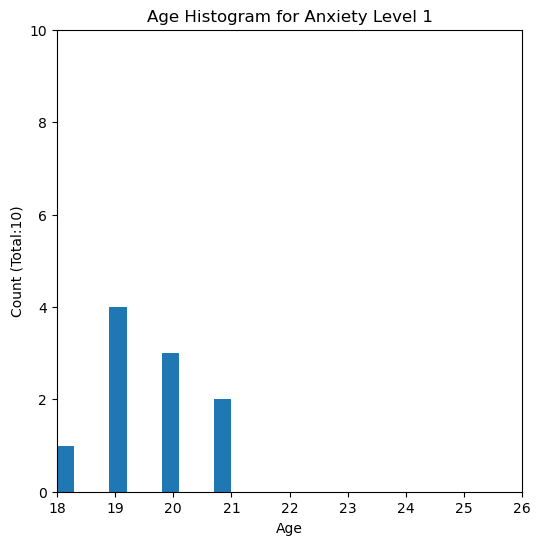

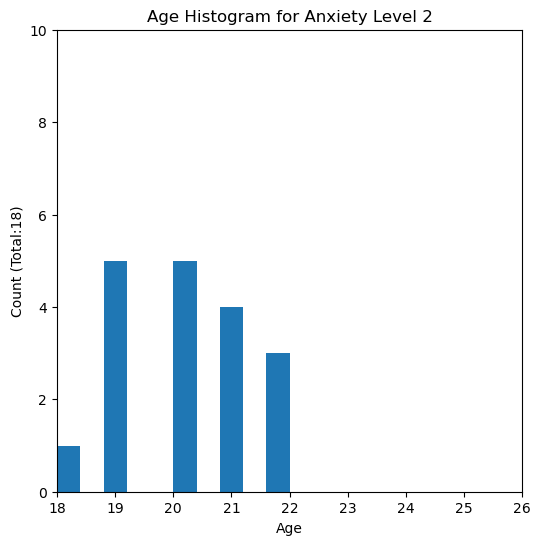

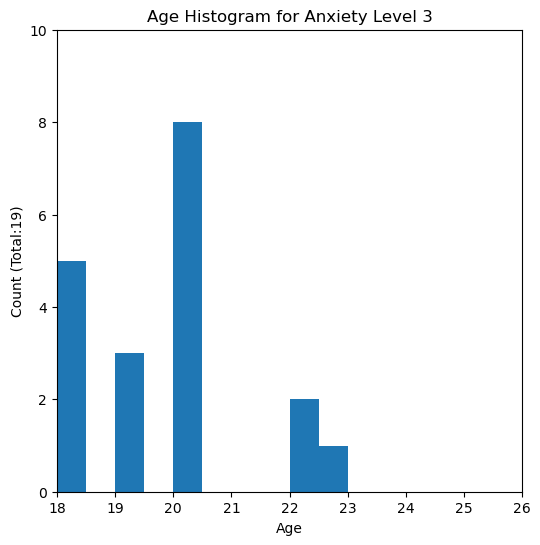

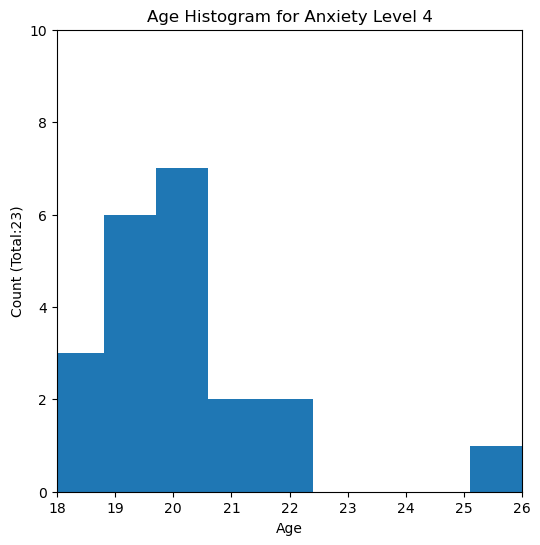

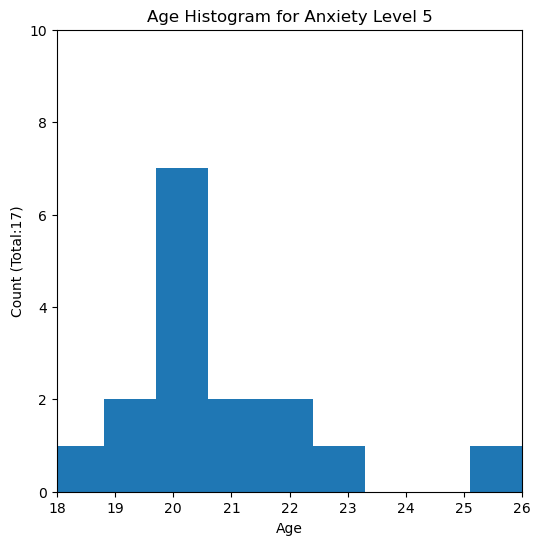

In [109]:
age_anxiety_lists =[age_1a,age_2a,age_3a,age_4a,age_5a]
plt.figure(figsize=(6,6))

for level, ages in enumerate(age_anxiety_lists,start=1):
    plt.figure(figsize=(6,6))
    plt.hist(x=ages)
    plt.xlabel("Age")
    plt.ylabel(f"Count (Total:{len(ages)})")
    plt.ylim(0,10)
    plt.xlim(18,26)
    plt.title(f"Age Histogram for Anxiety Level {level}")
    plt.savefig(f"Age_Histogram_for_Anxiety_Level_{level}.jpg",bbox_inches="tight")
    plt.show()


# Gender

In [50]:
male_anxiety = df.loc[df['gender']=='Male','anxiety']

female_anxiety = df.loc[df['gender']=='Female','anxiety']

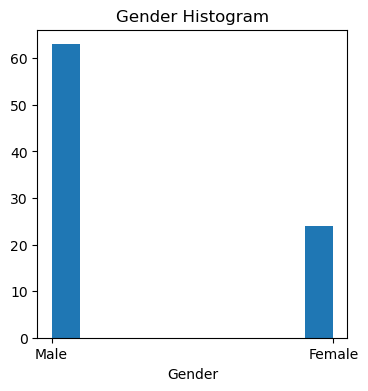

In [52]:
plt.figure(figsize=(4,4))
plt.hist(x=df['gender'])
plt.xlabel("Gender")
plt.title('Gender Histogram')
plt.savefig("Gender_Histogram.jpg",bbox_inches="tight")
plt.show()

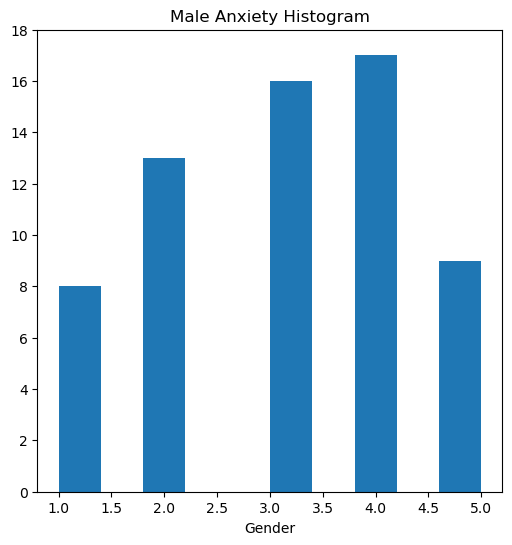

In [54]:
plt.figure(figsize=(6,6))
plt.hist(x=male_anxiety)
plt.xlabel("Gender")
plt.title('Male Anxiety Histogram')
plt.ylim(0,18)
plt.savefig("Male_Anxiety_Histogram.jpg",bbox_inches="tight")
plt.show()

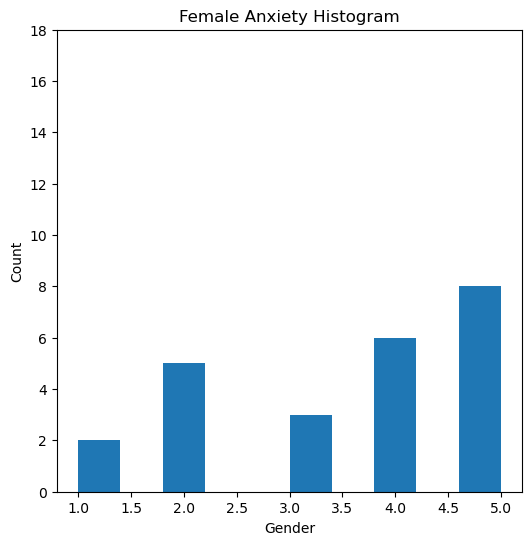

In [56]:
plt.figure(figsize=(6,6))
plt.hist(x=female_anxiety)
plt.xlabel("Gender")
plt.ylabel("Count")
plt.ylim(0,18)
plt.title('Female Anxiety Histogram')
plt.savefig("Female_Anxiety_Histogram.jpg",bbox_inches="tight")
plt.show()

# University

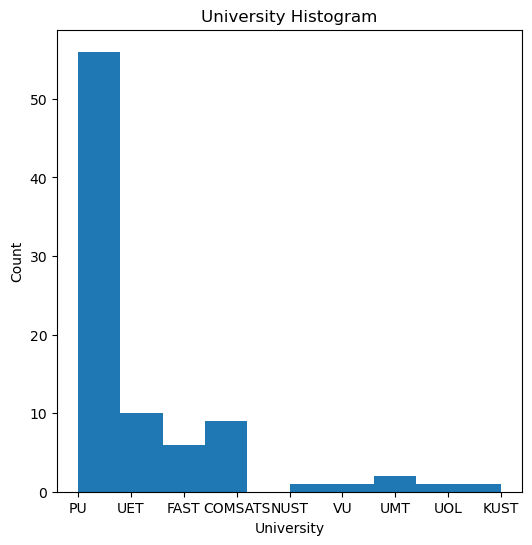

In [161]:
plt.figure(figsize=(6,6))
plt.hist(x=df['university'])
plt.title("University Histogram")
plt.ylabel("Count")
plt.xlabel("University")
plt.savefig("University_Histogram.png", bbox_inches='tight')
plt.show()

In [61]:
female_anxiety = df.loc[df['gender']=='Female','anxiety']

# Degree Level (Undergraduate vs Graduate)

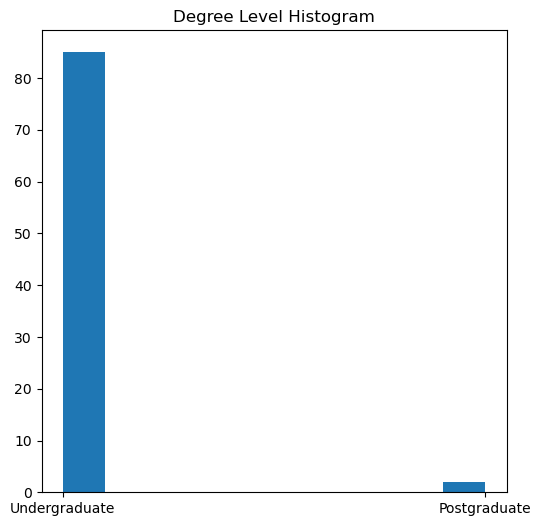

In [64]:
plt.figure(figsize=(6,6))
plt.hist(x=df['degree_level'])
plt.title("Degree Level Histogram")
plt.savefig("Degree Level Histogram.png", bbox_inches='tight')
plt.show()

In [66]:
graduate_anxiety = df.loc[df['degree_level']=='Postgraduate','anxiety']
undergraduate_anxiety = df.loc[df['degree_level']=='Undergraduate','anxiety']

In [68]:
graduates = df.loc[df['degree_level']=='Postgraduate']

graduates

,gender,age,university,degree_level,degree_major,academic_year,cgpa,residential_status,campus_discrimination,sports_engagement,...,study_satisfaction,academic_workload,academic_pressure,financial_concerns,social_relationships,depression,anxiety,isolation,future_insecurity,stress_relief_activities
1,Male,20,UET,Postgraduate,Computer Science,3rd year,3.0-3.5,Off-Campus,No,1-3 times,...,5,4,4,1,3,3,3,3,4,Online Entertainment
6,Male,26,PU,Postgraduate,Data Science,1st year,2.5-3.0,On-Campus,Yes,1-3 times,...,4,4,4,5,2,5,4,4,5,"Social Connections, Online Entertainment"


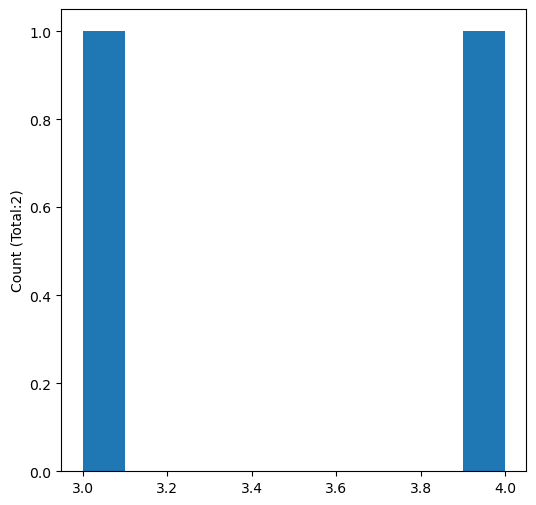

In [70]:
plt.figure(figsize=(6,6))
plt.hist(x=graduate_anxiety)
plt.ylabel(f"Count (Total:{len(graduate_anxiety)})")
plt.show()

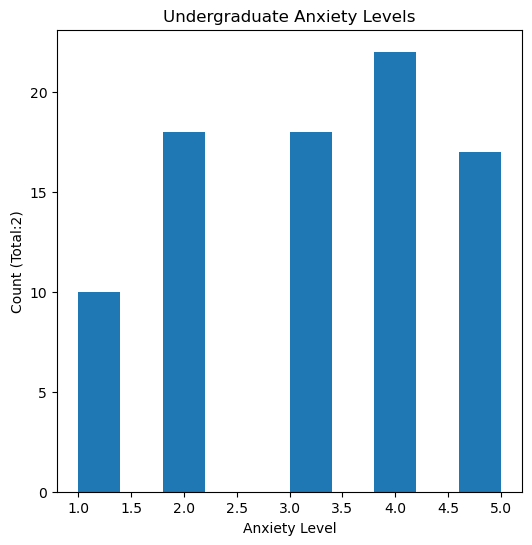

In [72]:
plt.figure(figsize=(6,6))
plt.hist(x=undergraduate_anxiety)
plt.ylabel(f"Count (Total:{len(graduate_anxiety)})")
plt.xlabel("Anxiety Level")
plt.title("Undergraduate Anxiety Levels")
plt.show()

# Major

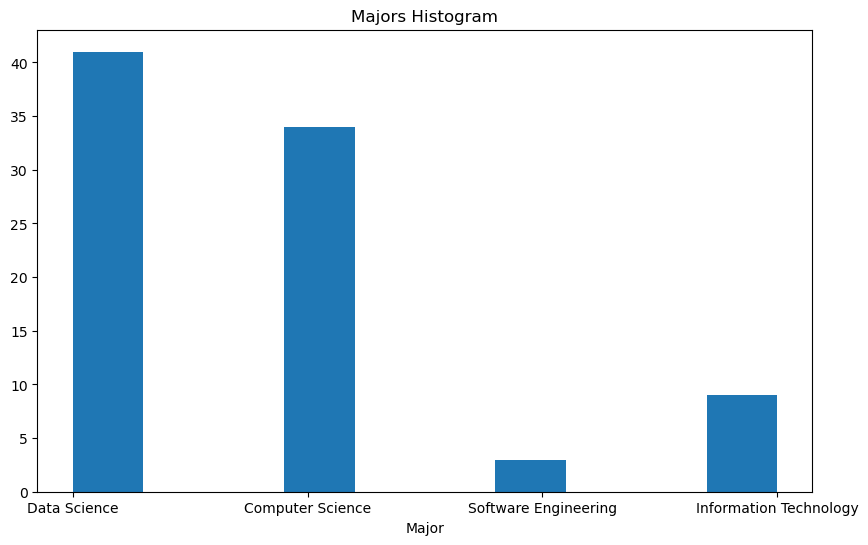

In [139]:
plt.figure(figsize=(10,6))
plt.hist(x=df['degree_major'])
plt.title('Majors Histogram')
plt.xlabel("Major")
plt.title('Majors Histogram')
plt.savefig('Majors_histogram.png', bbox_inches='tight')
plt.show()

In [157]:
DS_anxiety = df.loc[df['degree_major']=='Data Science','anxiety']
CS_anxiety = df.loc[df['degree_major']=='Computer Science','anxiety']
SE_anxiety = df.loc[df['degree_major']=='Software Engineering','anxiety']
IT_anxiety = df.loc[df['degree_major']=='Information Technology','anxiety']

major_list = [DS_anxiety, CS_anxiety, SE_anxiety, IT_anxiety]


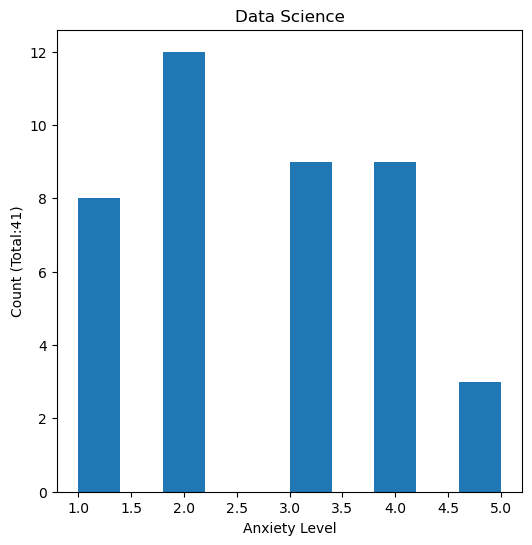

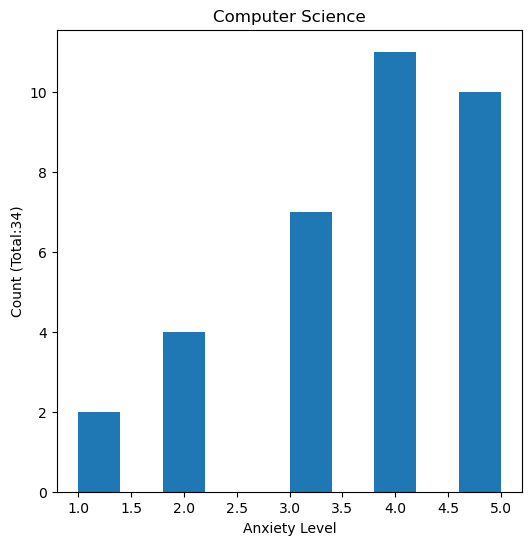

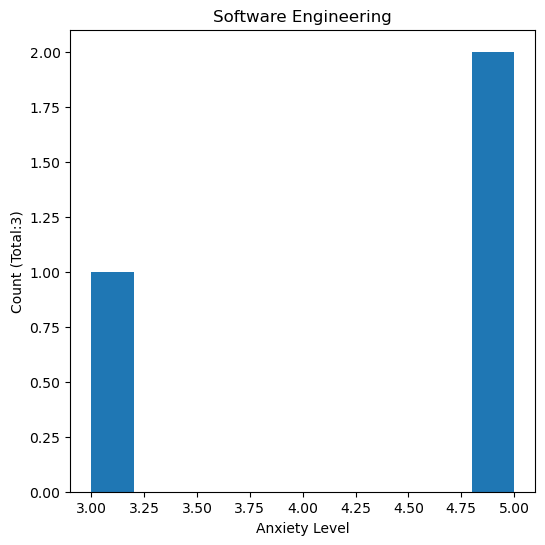

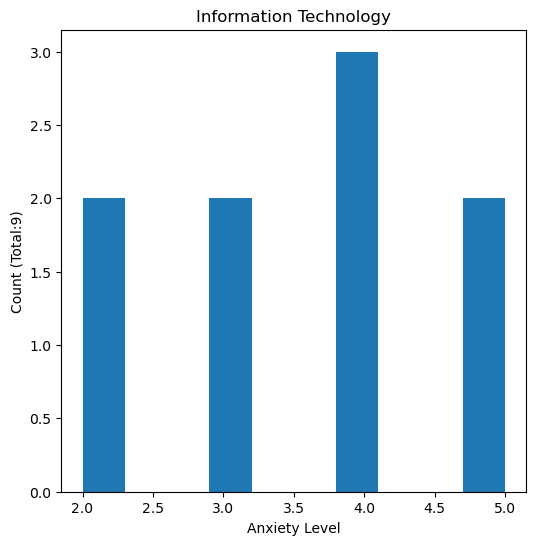

In [159]:
for major, major_name in zip(major_list, df['degree_major'].unique()):
    plt.figure(figsize=(6,6))
    plt.title(f"{major_name}")
    plt.xlabel("Anxiety Level")
    plt.ylabel(f"Count (Total:{len(major)})")
    plt.hist(x=major)
    plt.savefig(f"{major_name}_AnxietyLevel.png", bbox_inches='tight')
    plt.show()


# Other Stuff 

In [83]:
description(df_mC)

Shape of Dataset:
(87, 5)

Data Types of Columns:
gender          object
age              int64
university      object
degree_level    object
degree_major    object
dtype: object

Target & Target Counts:
degree_major
Data Science              41
Computer Science          34
Information Technology     9
Software Engineering       3
Name: count, dtype: int64

Missing Value Counts:
gender          0
age             0
university      0
degree_level    0
degree_major    0
dtype: int64

Missing Value Percentages:
gender          0
age             0
university      0
degree_level    0
degree_major    0
dtype: int64

First Five Rows
   gender  age university   degree_level      degree_major
0    Male   20         PU  Undergraduate      Data Science
1    Male   20        UET   Postgraduate  Computer Science
2    Male   20       FAST  Undergraduate  Computer Science
3    Male   20        UET  Undergraduate  Computer Science
4  Female   20        UET  Undergraduate  Computer Science



In [85]:
def description_specific(df):
    missing_count = df.shape[0] - df.count() # Number of rows minus number of non-NA rows.
    data_types = df.dtypes

    print(f"Data Types of Columns:\n{data_types}\n")
    print(f"Missing Value Counts:\n{missing_count}\n")    
    print("Unique Values of each column:\n")
    for i in df.columns: # shows unique values per column
        print(f"  {i}:{df[i].unique()}\n") 
    


In [87]:
description_specific(df_mC)

Data Types of Columns:
gender          object
age              int64
university      object
degree_level    object
degree_major    object
dtype: object

Missing Value Counts:
gender          0
age             0
university      0
degree_level    0
degree_major    0
dtype: int64

Unique Values of each column:

  gender:['Male' 'Female']

  age:[20 26 22 23 21 19 18 17]

  university:['PU' 'UET' 'FAST' 'COMSATS' 'NUST' 'VU' 'UMT' 'UOL' 'KUST']

  degree_level:['Undergraduate' 'Postgraduate']

  degree_major:['Data Science' 'Computer Science' 'Software Engineering'
 'Information Technology']



In [89]:
for i in df_mC.columns:
    print(f"{i}:{df[i].unique()}\n")

gender:['Male' 'Female']

age:[20 26 22 23 21 19 18 17]

university:['PU' 'UET' 'FAST' 'COMSATS' 'NUST' 'VU' 'UMT' 'UOL' 'KUST']

degree_level:['Undergraduate' 'Postgraduate']

degree_major:['Data Science' 'Computer Science' 'Software Engineering'
 'Information Technology']



In [91]:
df_mC.columns

Index(['gender', 'age', 'university', 'degree_level', 'degree_major'], dtype='object')

In [93]:
df_mC.describe()

,age
count,87.000000
mean,19.942529
std,1.623636
min,17.000000
25%,19.000000
50%,20.000000
75%,21.000000
max,26.000000
